In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [105]:
import os
import pandas as pd

# Universal dataset resolver (works seamlessly in Kaggle, Colab, or Local Windows/Linux)
candidate_paths = [
    '/kaggle/input/datasets/avnishahlawat/agmarket/agmarknet_india_historical_prices_2024_2025.csv',
    '/kaggle/input/agmarket/agmarknet_india_historical_prices_2024_2025.csv',
    'agmarknet_india_historical_prices_2024_2025.csv',
    r'd:\mydata\D Drive\agmarknet_india_historical_prices_2024_2025.csv',
    r'c:\Users\avnis\OneDrive\Desktop\ag-agi\agmarknet_india_historical_prices_2024_2025.csv'
]

price_path = None
for p in candidate_paths:
    if os.path.exists(p):
        price_path = p
        break

if price_path is None:
    for root, dirs, files in os.walk('.'):
        if 'agmarknet_india_historical_prices_2024_2025.csv' in files:
            price_path = os.path.join(root, 'agmarknet_india_historical_prices_2024_2025.csv')
            break

if price_path is None:
    price_path = candidate_paths[0]

df = pd.read_csv(price_path)
print(f'Dataset successfully loaded from: {price_path}')
print('Dataset shape:', df.shape)


Dataset loaded successfully.
Shape: (1118899, 11)


In [106]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Columns:
['Sl no.', 'District Name', 'Market Name', 'Commodity', 'Variety', 'Grade', 'Min Price (Rs./Quintal)', 'Max Price (Rs./Quintal)', 'Modal Price (Rs./Quintal)', 'Price Date', 'State']

Data Types:
Sl no.                         int64
District Name                 object
Market Name                   object
Commodity                     object
Variety                       object
Grade                         object
Min Price (Rs./Quintal)      float64
Max Price (Rs./Quintal)      float64
Modal Price (Rs./Quintal)    float64
Price Date                    object
State                         object
dtype: object

First 5 Rows:


,Sl no.,District Name,Market Name,Commodity,Variety,Grade,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Price Date,State
0,1,Auraiya,Achalda,Wheat,Dara,FAQ,2350.0,2550.0,2450.0,05 Apr 2025,Uttar Pradesh
1,2,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2500.0,2470.0,14 Jun 2025,Uttar Pradesh
2,3,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2500.0,2470.0,23 Jun 2025,Uttar Pradesh
3,4,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2520.0,2470.0,26 Jun 2025,Uttar Pradesh
4,5,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2550.0,2500.0,03 Jun 2025,Uttar Pradesh


In [107]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Sl no.                       0
District Name                0
Market Name                  0
Commodity                    0
Variety                      0
Grade                        0
Min Price (Rs./Quintal)      0
Max Price (Rs./Quintal)      0
Modal Price (Rs./Quintal)    0
Price Date                   0
State                        0
dtype: int64

Total Duplicate Rows:
0


In [108]:
df["Price Date"] = pd.to_datetime(
    df["Price Date"],
    dayfirst=True,
    errors="coerce"
)

df = df.drop(columns=["Sl no."])

print("Shape:", df.shape)
print("Invalid dates:", df["Price Date"].isna().sum())
print("Date range:", df["Price Date"].min(), "to", df["Price Date"].max())

Shape: (1118899, 10)
Invalid dates: 0
Date range: 2024-08-15 00:00:00 to 2025-08-14 00:00:00


In [109]:
price_min = "Min Price (Rs./Quintal)"
price_max = "Max Price (Rs./Quintal)"
price_modal = "Modal Price (Rs./Quintal)"

invalid_min_max = df[price_min] > df[price_max]
invalid_modal = (
    (df[price_modal] < df[price_min]) |
    (df[price_modal] > df[price_max])
)

print("Min > Max:", invalid_min_max.sum())
print("Modal outside Min-Max:", invalid_modal.sum())

Min > Max: 470
Modal outside Min-Max: 1200


In [110]:
# Remove records where minimum price is greater than maximum price
df = df[df[price_min] <= df[price_max]].copy()

# Mark invalid modal prices as missing
invalid_modal = (
    (df[price_modal] < df[price_min]) |
    (df[price_modal] > df[price_max])
)

df.loc[invalid_modal, price_modal] = np.nan

print("Shape after cleaning:", df.shape)
print("Invalid modal values converted to NaN:", invalid_modal.sum())
print("Remaining missing modal prices:", df[price_modal].isna().sum())

Shape after cleaning: (1118429, 10)
Invalid modal values converted to NaN: 730
Remaining missing modal prices: 730


In [111]:
df = df.dropna(subset=[price_modal]).copy()

print("Shape after removing invalid modal prices:", df.shape)
print("Missing modal prices:", df[price_modal].isna().sum())

Shape after removing invalid modal prices: (1117699, 10)
Missing modal prices: 0


In [112]:
selected_commodities = ["Wheat", "Maize", "Brinjal"]

commodity_df = df[
    df["Commodity"].isin(selected_commodities)
].copy()

print("Selected commodities:")
print(commodity_df["Commodity"].value_counts())

print("\nShape:", commodity_df.shape)

Selected commodities:
Commodity
Brinjal    111774
Wheat       71286
Maize       54255
Name: count, dtype: int64

Shape: (237315, 10)


In [113]:
market_coverage = (
    commodity_df
    .groupby(["Commodity", "Market Name"])["Price Date"]
    .nunique()
    .reset_index(name="Unique_Days")
    .sort_values(["Commodity", "Unique_Days"], ascending=[True, False])
)

top_markets = (
    market_coverage
    .groupby("Commodity")
    .head(5)
)

display(top_markets)

,Commodity,Market Name,Unique_Days
271,Brinjal,Khatra,365
237,Brinjal,Kalipur,364
92,Brinjal,Birbhum,363
93,Brinjal,Bishnupur(Bankura),363
32,Brinjal,Asansol,361
583,Maize,Anjad,335
803,Maize,Khargone,333
635,Maize,Bhikangaon,327
846,Maize,Manawar,322
682,Maize,Dhamnod,321


In [114]:
selected_markets = {
    "Wheat": [
        "Bishnupur(Bankura)",
        "Durgapur",
        "Asansol",
        "Raibareilly",
        "Bolpur"
    ],
    "Maize": [
        "Anjad",
        "Khargone",
        "Bhikangaon",
        "Manawar",
        "Dhamnod"
    ],
    "Brinjal": [
        "Khatra",
        "Kalipur",
        "Birbhum",
        "Bishnupur(Bankura)",
        "Asansol"
    ]
}

selected_pairs = [
    (commodity, market)
    for commodity, markets in selected_markets.items()
    for market in markets
]

selected_df = commodity_df[
    commodity_df.set_index(["Commodity", "Market Name"]).index.isin(selected_pairs)
].copy()

print("Selected shape:", selected_df.shape)
print("Selected series:", len(selected_pairs))

Selected shape: (6906, 10)
Selected series: 15


In [115]:
price_col = "Modal Price (Rs./Quintal)"

daily_df = (
    selected_df
    .groupby(
        ["Commodity", "Market Name", "Price Date"],
        as_index=False
    )
    .agg(
        Modal_Price=(price_col, "median")
    )
)

print("Daily dataset shape:", daily_df.shape)

print(
    "Duplicate commodity-market-date groups:",
    daily_df.duplicated(
        ["Commodity", "Market Name", "Price Date"]
    ).sum()
)

Daily dataset shape: (5243, 4)
Duplicate commodity-market-date groups: 0


In [116]:
coverage = (
    daily_df
    .groupby(["Commodity", "Market Name"])["Price Date"]
    .nunique()
    .reset_index(name="Unique_Days")
)

coverage["Coverage_Percent"] = (
    coverage["Unique_Days"] / 365 * 100
)

display(coverage)

,Commodity,Market Name,Unique_Days,Coverage_Percent
0,Brinjal,Asansol,361,98.904110
1,Brinjal,Birbhum,363,99.452055
2,Brinjal,Bishnupur(Bankura),363,99.452055
3,Brinjal,Kalipur,364,99.726027
4,Brinjal,Khatra,365,100.000000
5,Maize,Anjad,335,91.780822
6,Maize,Bhikangaon,327,89.589041
7,Maize,Dhamnod,321,87.945205
8,Maize,Khargone,333,91.232877
9,Maize,Manawar,322,88.219178


In [117]:
filled_series = []

for (commodity, market), group in daily_df.groupby(
    ["Commodity", "Market Name"]
):
    
    group = group.sort_values("Price Date").set_index("Price Date")
    
    group = group.asfreq("D")
    
    group["Commodity"] = commodity
    group["Market Name"] = market
    
    group["Modal_Price"] = group["Modal_Price"].interpolate(
        method="linear",
        limit=3,
        limit_area="inside"
    )
    
    filled_series.append(group.reset_index())

daily_df = pd.concat(filled_series, ignore_index=True)

print("Shape after daily reindexing:", daily_df.shape)
print("Remaining missing prices:", daily_df["Modal_Price"].isna().sum())

Shape after daily reindexing: (5466, 4)
Remaining missing prices: 1


In [118]:
print("Non-positive prices:", (daily_df["Modal_Price"] <= 0).sum())

price_summary = (
    daily_df
    .groupby("Commodity")["Modal_Price"]
    .agg(["min", "max", "mean", "median"])
)

display(price_summary)

Non-positive prices: 0


,min,max,mean,median
Commodity,,,,
Brinjal,1000.0,9000.0,3444.597039,3400.0
Maize,1300.0,2951.0,2076.172289,2100.0
Wheat,2300.0,3000.0,2649.510005,2600.0


## 17. Feature Engineering

Time-series forecasting requires features that describe recent price
behavior and seasonal patterns.

The following features are created:

- Day of week
- Month
- Week of year
- Lagged prices: 1, 7, 14, and 30 days
- 7-day rolling mean and standard deviation
- 30-day rolling mean and standard deviation

All lag and rolling features are calculated separately for each
commodity-market series.

In [119]:
daily_df = daily_df.sort_values(
    ["Commodity", "Market Name", "Price Date"]
).reset_index(drop=True)

daily_df["Day_of_Week"] = daily_df["Price Date"].dt.dayofweek
daily_df["Month"] = daily_df["Price Date"].dt.month
daily_df["Week_of_Year"] = daily_df["Price Date"].dt.isocalendar().week.astype(int)

daily_df.head()

,Price Date,Commodity,Market Name,Modal_Price,Day_of_Week,Month,Week_of_Year
0,2024-08-15,Brinjal,Asansol,4300.0,3,8,33
1,2024-08-16,Brinjal,Asansol,5000.0,4,8,33
2,2024-08-17,Brinjal,Asansol,4000.0,5,8,33
3,2024-08-18,Brinjal,Asansol,3700.0,6,8,33
4,2024-08-19,Brinjal,Asansol,3900.0,0,8,34


In [120]:
for lag in [1, 7, 14, 30]:
    daily_df[f"Lag_{lag}"] = (
        daily_df
        .groupby(["Commodity", "Market Name"])["Modal_Price"]
        .shift(lag)
    )

daily_df.head(35)

,Price Date,Commodity,Market Name,Modal_Price,Day_of_Week,Month,Week_of_Year,Lag_1,Lag_7,Lag_14,Lag_30
0,2024-08-15,Brinjal,Asansol,4300.0,3,8,33,NaN,NaN,NaN,NaN
1,2024-08-16,Brinjal,Asansol,5000.0,4,8,33,4300.0,NaN,NaN,NaN
2,2024-08-17,Brinjal,Asansol,4000.0,5,8,33,5000.0,NaN,NaN,NaN
3,2024-08-18,Brinjal,Asansol,3700.0,6,8,33,4000.0,NaN,NaN,NaN
4,2024-08-19,Brinjal,Asansol,3900.0,0,8,34,3700.0,NaN,NaN,NaN
5,2024-08-20,Brinjal,Asansol,4000.0,1,8,34,3900.0,NaN,NaN,NaN
6,2024-08-21,Brinjal,Asansol,4200.0,2,8,34,4000.0,NaN,NaN,NaN
7,2024-08-22,Brinjal,Asansol,4400.0,3,8,34,4200.0,4300.0,NaN,NaN
8,2024-08-23,Brinjal,Asansol,4200.0,4,8,34,4400.0,5000.0,NaN,NaN
9,2024-08-24,Brinjal,Asansol,3900.0,5,8,34,4200.0,4000.0,NaN,NaN


In [121]:
previous_price = (
    daily_df
    .groupby(["Commodity", "Market Name"])["Modal_Price"]
    .shift(1)
)

daily_df["Rolling_Mean_7"] = (
    previous_price
    .groupby([
        daily_df["Commodity"],
        daily_df["Market Name"]
    ])
    .transform(lambda x: x.rolling(7).mean())
)

daily_df["Rolling_Std_7"] = (
    previous_price
    .groupby([
        daily_df["Commodity"],
        daily_df["Market Name"]
    ])
    .transform(lambda x: x.rolling(7).std())
)

daily_df["Rolling_Mean_30"] = (
    previous_price
    .groupby([
        daily_df["Commodity"],
        daily_df["Market Name"]
    ])
    .transform(lambda x: x.rolling(30).mean())
)

daily_df["Rolling_Std_30"] = (
    previous_price
    .groupby([
        daily_df["Commodity"],
        daily_df["Market Name"]
    ])
    .transform(lambda x: x.rolling(30).std())
)

daily_df.head(35)

,Price Date,Commodity,Market Name,Modal_Price,Day_of_Week,Month,Week_of_Year,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_Mean_7,Rolling_Std_7,Rolling_Mean_30,Rolling_Std_30
0,2024-08-15,Brinjal,Asansol,4300.0,3,8,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-08-16,Brinjal,Asansol,5000.0,4,8,33,4300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-08-17,Brinjal,Asansol,4000.0,5,8,33,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-08-18,Brinjal,Asansol,3700.0,6,8,33,4000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-08-19,Brinjal,Asansol,3900.0,0,8,34,3700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2024-08-20,Brinjal,Asansol,4000.0,1,8,34,3900.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2024-08-21,Brinjal,Asansol,4200.0,2,8,34,4000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2024-08-22,Brinjal,Asansol,4400.0,3,8,34,4200.0,4300.0,NaN,NaN,4157.142857,419.750493,NaN,NaN
8,2024-08-23,Brinjal,Asansol,4200.0,4,8,34,4400.0,5000.0,NaN,NaN,4171.428571,427.060830,NaN,NaN
9,2024-08-24,Brinjal,Asansol,3900.0,5,8,34,4200.0,4000.0,NaN,NaN,4057.142857,229.906813,NaN,NaN


In [122]:
feature_columns = [
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_30",
    "Rolling_Mean_7",
    "Rolling_Std_7",
    "Rolling_Mean_30",
    "Rolling_Std_30"
]

print("Missing values in engineered features:")
print(daily_df[feature_columns].isnull().sum())

Missing values in engineered features:
Lag_1               16
Lag_7              106
Lag_14             211
Lag_30             451
Rolling_Mean_7     112
Rolling_Std_7      112
Rolling_Mean_30    461
Rolling_Std_30     461
dtype: int64


## 19. Preparing the Modeling Dataset

The initial rows of each commodity-market series contain missing lag and
rolling features because sufficient historical observations are not yet
available.

These rows are removed from the modeling dataset. No statistical
imputation is performed because the missing values represent unavailable
historical information rather than missing measurements.

In [123]:
model_df = daily_df.dropna(
    subset=feature_columns
).copy()

print("Original rows:", len(daily_df))
print("Modeling rows:", len(model_df))
print("Rows removed:", len(daily_df) - len(model_df))

print("\nRemaining missing values:")
print(model_df[feature_columns].isnull().sum().sum())

Original rows: 5466
Modeling rows: 5005
Rows removed: 461

Remaining missing values:
0


## Historical Weather Data Integration

In [124]:
weather_locations = (
    daily_df[["Commodity", "Market Name"]]
    .drop_duplicates()
    .sort_values(["Commodity", "Market Name"])
    .reset_index(drop=True)
)

print("Number of selected locations:", len(weather_locations))
display(weather_locations)

Number of selected locations: 15


,Commodity,Market Name
0,Brinjal,Asansol
1,Brinjal,Birbhum
2,Brinjal,Bishnupur(Bankura)
3,Brinjal,Kalipur
4,Brinjal,Khatra
5,Maize,Anjad
6,Maize,Bhikangaon
7,Maize,Dhamnod
8,Maize,Khargone
9,Maize,Manawar


In [125]:
location_mapping = (
    selected_df[
        ["Commodity", "Market Name", "District Name", "State"]
    ]
    .drop_duplicates()
    .sort_values(["Commodity", "Market Name"])
)

display(location_mapping)

,Commodity,Market Name,District Name,State
590516,Brinjal,Asansol,Paschim Bardhaman,West Bengal
593322,Brinjal,Birbhum,Birbhum,West Bengal
593685,Brinjal,Bishnupur(Bankura),Bankura,West Bengal
600842,Brinjal,Kalipur,Hooghly,West Bengal
602412,Brinjal,Khatra,Bankura,West Bengal
91684,Maize,Anjad,Badwani,Madhya Pradesh
93373,Maize,Bhikangaon,Khargone,Madhya Pradesh
95233,Maize,Dhamnod,Dhar,Madhya Pradesh
96746,Maize,Khargone,Khargone,Madhya Pradesh
97564,Maize,Manawar,Dhar,Madhya Pradesh


In [126]:
location_mapping = (
    selected_df[
        ["Market Name", "District Name", "State"]
    ]
    .drop_duplicates()
    .sort_values(["State", "District Name", "Market Name"])
    .reset_index(drop=True)
)

print("Unique market locations:", len(location_mapping))

display(location_mapping)

Unique market locations: 13


,Market Name,District Name,State
0,Anjad,Badwani,Madhya Pradesh
1,Dhamnod,Dhar,Madhya Pradesh
2,Manawar,Dhar,Madhya Pradesh
3,Bhikangaon,Khargone,Madhya Pradesh
4,Khargone,Khargone,Madhya Pradesh
5,Raibareilly,Raebarelli,Uttar Pradesh
6,Bishnupur(Bankura),Bankura,West Bengal
7,Khatra,Bankura,West Bengal
8,Birbhum,Birbhum,West Bengal
9,Bolpur,Birbhum,West Bengal


##  Preparing Locations for Geocoding

In [127]:
location_mapping["Search_Query"] = (
    location_mapping["Market Name"] + ", " +
    location_mapping["District Name"] + ", " +
    location_mapping["State"] + ", India"
)

display(location_mapping)

,Market Name,District Name,State,Search_Query
0,Anjad,Badwani,Madhya Pradesh,"Anjad, Badwani, Madhya Pradesh, India"
1,Dhamnod,Dhar,Madhya Pradesh,"Dhamnod, Dhar, Madhya Pradesh, India"
2,Manawar,Dhar,Madhya Pradesh,"Manawar, Dhar, Madhya Pradesh, India"
3,Bhikangaon,Khargone,Madhya Pradesh,"Bhikangaon, Khargone, Madhya Pradesh, India"
4,Khargone,Khargone,Madhya Pradesh,"Khargone, Khargone, Madhya Pradesh, India"
5,Raibareilly,Raebarelli,Uttar Pradesh,"Raibareilly, Raebarelli, Uttar Pradesh, India"
6,Bishnupur(Bankura),Bankura,West Bengal,"Bishnupur(Bankura), Bankura, West Bengal, India"
7,Khatra,Bankura,West Bengal,"Khatra, Bankura, West Bengal, India"
8,Birbhum,Birbhum,West Bengal,"Birbhum, Birbhum, West Bengal, India"
9,Bolpur,Birbhum,West Bengal,"Bolpur, Birbhum, West Bengal, India"


## Geocoding Market Locations

In [128]:
geocoded_locations = []

for _, row in location_mapping.iterrows():
    query = row["Market Name"]

    response = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={
            "name": query,
            "count": 5,
            "language": "en",
            "format": "json"
        },
        timeout=20
    )

    data = response.json()

    results = data.get("results", [])

    # Prefer an Indian result
    india_results = [
        r for r in results
        if r.get("country_code") == "IN"
    ]

    if india_results:
        result = india_results[0]

        geocoded_locations.append({
            "Market Name": row["Market Name"],
            "District Name": row["District Name"],
            "State": row["State"],
            "Latitude": result["latitude"],
            "Longitude": result["longitude"],
            "Geocoded_Name": result.get("name"),
            "Country": result.get("country")
        })
    else:
        geocoded_locations.append({
            "Market Name": row["Market Name"],
            "District Name": row["District Name"],
            "State": row["State"],
            "Latitude": np.nan,
            "Longitude": np.nan,
            "Geocoded_Name": None,
            "Country": None
        })

    time.sleep(0.2)

geocoded_df = pd.DataFrame(geocoded_locations)

display(geocoded_df)

,Market Name,District Name,State,Latitude,Longitude,Geocoded_Name,Country
0,Anjad,Badwani,Madhya Pradesh,22.04171,75.05519,Anjad,India
1,Dhamnod,Dhar,Madhya Pradesh,22.20928,75.47057,Dhāmnod,India
2,Manawar,Dhar,Madhya Pradesh,22.23566,75.08917,Manāwar,India
3,Bhikangaon,Khargone,Madhya Pradesh,21.86764,75.96391,Bhikangaon,India
4,Khargone,Khargone,Madhya Pradesh,21.82292,75.61394,Khargone,India
5,Raibareilly,Raebarelli,Uttar Pradesh,NaN,NaN,None,None
6,Bishnupur(Bankura),Bankura,West Bengal,NaN,NaN,None,None
7,Khatra,Bankura,West Bengal,22.97617,86.85462,Khātra,India
8,Birbhum,Birbhum,West Bengal,NaN,NaN,None,None
9,Bolpur,Birbhum,West Bengal,23.66278,87.69695,Bolpur,India


In [129]:
failed_locations = geocoded_df[
    geocoded_df["Latitude"].isna()
].copy()

retry_locations = []

for _, row in failed_locations.iterrows():
    query = row["District Name"]

    response = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={
            "name": query,
            "count": 5,
            "language": "en",
            "format": "json"
        },
        timeout=20
    )

    data = response.json()

    results = [
        r for r in data.get("results", [])
        if r.get("country_code") == "IN"
    ]

    if results:
        result = results[0]

        retry_locations.append({
            "Market Name": row["Market Name"],
            "District Name": row["District Name"],
            "State": row["State"],
            "Latitude": result["latitude"],
            "Longitude": result["longitude"],
            "Geocoded_Name": result.get("name"),
            "Country": result.get("country")
        })
    else:
        retry_locations.append({
            "Market Name": row["Market Name"],
            "District Name": row["District Name"],
            "State": row["State"],
            "Latitude": np.nan,
            "Longitude": np.nan,
            "Geocoded_Name": None,
            "Country": None
        })

    time.sleep(0.2)

retry_df = pd.DataFrame(retry_locations)

display(retry_df)

,Market Name,District Name,State,Latitude,Longitude,Geocoded_Name,Country
0,Raibareilly,Raebarelli,Uttar Pradesh,NaN,NaN,None,None
1,Bishnupur(Bankura),Bankura,West Bengal,23.23241,87.07160,Bānkura,India
2,Birbhum,Birbhum,West Bengal,NaN,NaN,None,None
3,Kalipur,Hooghly,West Bengal,22.90877,88.39674,Hugli,India


In [130]:
# Alternate names for the two unresolved locations

alternate_queries = {
    "Raibareilly": "Raebareli",
    "Birbhum": "Suri"
}

final_geocoded = []

for market, query in alternate_queries.items():

    response = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={
            "name": query,
            "count": 5,
            "language": "en",
            "format": "json"
        },
        timeout=20
    )

    results = [
        r for r in response.json().get("results", [])
        if r.get("country_code") == "IN"
    ]

    if results:
        result = results[0]

        final_geocoded.append({
            "Market Name": market,
            "Latitude": result["latitude"],
            "Longitude": result["longitude"],
            "Geocoded_Name": result.get("name"),
            "Country": result.get("country")
        })
    else:
        final_geocoded.append({
            "Market Name": market,
            "Latitude": np.nan,
            "Longitude": np.nan,
            "Geocoded_Name": None,
            "Country": None
        })

display(pd.DataFrame(final_geocoded))

,Market Name,Latitude,Longitude,Geocoded_Name,Country
0,Raibareilly,26.23090,81.23315,Raebareli,India
1,Birbhum,23.90806,87.52773,Siuri,India


In [131]:
# Combine all successful geocoding results

coordinates_1 = geocoded_df.dropna(subset=["Latitude"])[
    ["Market Name", "Latitude", "Longitude", "Geocoded_Name", "Country"]
]

coordinates_2 = retry_df.dropna(subset=["Latitude"])[
    ["Market Name", "Latitude", "Longitude", "Geocoded_Name", "Country"]
]

coordinates_3 = pd.DataFrame(final_geocoded)[
    ["Market Name", "Latitude", "Longitude", "Geocoded_Name", "Country"]
]

final_coordinates = pd.concat(
    [coordinates_1, coordinates_2, coordinates_3],
    ignore_index=True
)

final_coordinates = (
    final_coordinates
    .drop_duplicates(subset=["Market Name"])
    .sort_values("Market Name")
    .reset_index(drop=True)
)

print("Total mapped locations:", len(final_coordinates))
print("Missing coordinates:", final_coordinates["Latitude"].isna().sum())

display(final_coordinates)

Total mapped locations: 13
Missing coordinates: 0


,Market Name,Latitude,Longitude,Geocoded_Name,Country
0,Anjad,22.04171,75.05519,Anjad,India
1,Asansol,23.68333,86.98333,Asansol,India
2,Bhikangaon,21.86764,75.96391,Bhikangaon,India
3,Birbhum,23.90806,87.52773,Siuri,India
4,Bishnupur(Bankura),23.23241,87.07160,Bānkura,India
5,Bolpur,23.66278,87.69695,Bolpur,India
6,Dhamnod,22.20928,75.47057,Dhāmnod,India
7,Durgapur,23.51583,87.30801,Durgapur,India
8,Kalipur,22.90877,88.39674,Hugli,India
9,Khargone,21.82292,75.61394,Khargone,India


## Downloading Historical Weather Data

In [132]:
weather_records = []

weather_start = "2024-08-15"
weather_end = "2025-08-14"

for _, row in final_coordinates.iterrows():

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": row["Latitude"],
            "longitude": row["Longitude"],
            "start_date": weather_start,
            "end_date": weather_end,
            "daily": [
                "temperature_2m_mean",
                "temperature_2m_max",
                "temperature_2m_min",
                "precipitation_sum",
                "rain_sum",
                "wind_speed_10m_max"
            ],
            "timezone": "auto"
        },
        timeout=60
    )

    data = response.json()

    if "daily" not in data:
        print("Weather request failed:", row["Market Name"])
        continue

    daily_weather = pd.DataFrame(data["daily"])

    daily_weather["Market Name"] = row["Market Name"]

    weather_records.append(daily_weather)

weather_df = pd.concat(
    weather_records,
    ignore_index=True
)

print("Weather dataset shape:", weather_df.shape)

display(weather_df.head())

Weather dataset shape: (4745, 8)


,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,wind_speed_10m_max,Market Name
0,2024-08-15,28.0,32.5,25.0,2.2,2.2,15.2,Anjad
1,2024-08-16,28.3,32.2,24.7,1.2,1.2,11.3,Anjad
2,2024-08-17,28.3,32.0,24.7,0.5,0.5,10.9,Anjad
3,2024-08-18,28.8,32.5,25.2,2.4,2.4,10.5,Anjad
4,2024-08-19,29.0,33.2,25.8,5.5,5.5,13.5,Anjad


## Preparing weather data for merging

In [133]:
weather_df["Price Date"] = pd.to_datetime(weather_df["time"])

weather_df = weather_df.drop(columns=["time"])

print("Weather date range:")
print(weather_df["Price Date"].min(), "to", weather_df["Price Date"].max())

print("\nMissing values:")
print(weather_df.isnull().sum())

Weather date range:
2024-08-15 00:00:00 to 2025-08-14 00:00:00

Missing values:
temperature_2m_mean    0
temperature_2m_max     0
temperature_2m_min     0
precipitation_sum      0
rain_sum               0
wind_speed_10m_max     0
Market Name            0
Price Date             0
dtype: int64


## Merging price and weather data

In [134]:
weather_columns = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "rain_sum",
    "wind_speed_10m_max"
]

model_df = model_df.merge(
    weather_df[
        ["Market Name", "Price Date"] + weather_columns
    ],
    on=["Market Name", "Price Date"],
    how="left"
)

print("Merged dataset shape:", model_df.shape)

print("\nMissing weather values:")
print(model_df[weather_columns].isnull().sum())

Merged dataset shape: (5005, 21)

Missing weather values:
temperature_2m_mean    0
temperature_2m_max     0
temperature_2m_min     0
precipitation_sum      0
rain_sum               0
wind_speed_10m_max     0
dtype: int64


In [135]:
weather_summary = model_df[weather_columns].describe().T

display(weather_summary)

,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean,5005.0,26.068971,4.447618,11.7,22.9,26.9,28.9,37.6
temperature_2m_max,5005.0,31.864076,4.521728,17.3,28.9,31.6,34.4,44.8
temperature_2m_min,5005.0,21.277083,4.980490,6.5,17.2,23.1,25.3,32.2
precipitation_sum,5005.0,3.877762,9.584017,0.0,0.0,0.0,2.7,136.1
rain_sum,5005.0,3.877762,9.584017,0.0,0.0,0.0,2.7,136.1
wind_speed_10m_max,5005.0,13.712188,4.815676,4.8,10.3,12.7,16.4,44.0


In [136]:
correlation_columns = [
    "Modal_Price"
] + weather_columns

weather_correlation = (
    model_df[correlation_columns]
    .corr()["Modal_Price"]
    .sort_values(ascending=False)
)

display(weather_correlation)

Modal_Price            1.000000
rain_sum               0.232723
precipitation_sum      0.232723
temperature_2m_min     0.206677
temperature_2m_mean    0.071628
temperature_2m_max    -0.069709
wind_speed_10m_max    -0.090128
Name: Modal_Price, dtype: float64

In [137]:
weather_features = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "wind_speed_10m_max"
]

print("Selected weather features:")
print(weather_features)

print("\nModel dataset shape:", model_df.shape)

Selected weather features:
['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'wind_speed_10m_max']

Model dataset shape: (5005, 21)


## Time based train test split

In [138]:
test_days = 56

split_date = (
    model_df["Price Date"].max()
    - pd.Timedelta(days=test_days - 1)
)

train_df = model_df[
    model_df["Price Date"] < split_date
].copy()

test_df = model_df[
    model_df["Price Date"] >= split_date
].copy()

print("Split date:", split_date)

print("\nTraining period:")
print(train_df["Price Date"].min(), "to", train_df["Price Date"].max())

print("\nTesting period:")
print(test_df["Price Date"].min(), "to", test_df["Price Date"].max())

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

Split date: 2025-06-20 00:00:00

Training period:
2024-09-14 00:00:00 to 2025-06-19 00:00:00

Testing period:
2025-06-20 00:00:00 to 2025-08-14 00:00:00

Training rows: 4166
Testing rows: 839


In [139]:
test_df["Seasonal_Naive_Pred"] = (
    test_df
    .groupby(["Commodity", "Market Name"])["Modal_Price"]
    .shift(7)
)

# The first 7 observations of each test series may not have
# a corresponding 7-day value inside the test set.
baseline_df = test_df.dropna(
    subset=["Seasonal_Naive_Pred"]
).copy()

naive_mae = mean_absolute_error(
    baseline_df["Modal_Price"],
    baseline_df["Seasonal_Naive_Pred"]
)

naive_rmse = np.sqrt(
    mean_squared_error(
        baseline_df["Modal_Price"],
        baseline_df["Seasonal_Naive_Pred"]
    )
)

naive_mape = (
    np.mean(
        np.abs(
            (baseline_df["Modal_Price"] -
             baseline_df["Seasonal_Naive_Pred"])
            / baseline_df["Modal_Price"]
        )
    ) * 100
)

print("Seasonal Naive Baseline")
print("-----------------------")
print("MAE :", round(naive_mae, 2))
print("RMSE:", round(naive_rmse, 2))
print("MAPE:", round(naive_mape, 2), "%")

Seasonal Naive Baseline
-----------------------
MAE : 269.88
RMSE: 538.92
MAPE: 6.41 %


## LightGBM Model — Price Features Only

In [140]:
price_features = [
    "Day_of_Week",
    "Month",
    "Week_of_Year",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_30",
    "Rolling_Mean_7",
    "Rolling_Std_7",
    "Rolling_Mean_30",
    "Rolling_Std_30"
]

categorical_features = [
    "Commodity",
    "Market Name"
]

X_train = train_df[price_features + categorical_features].copy()
y_train = train_df["Modal_Price"]

X_test = test_df[price_features + categorical_features].copy()
y_test = test_df["Modal_Price"]

for col in categorical_features:
    X_train[col] = X_train[col].astype("category")
    X_test[col] = X_test[col].astype("category")

model_price_only = LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

model_price_only.fit(
    X_train,
    y_train,
    categorical_feature=categorical_features
)

print("LightGBM price-only model trained successfully.")

LightGBM price-only model trained successfully.


## Evaluating the Price-Only LightGBM Model

In [141]:
price_only_pred = model_price_only.predict(X_test)

price_only_mae = mean_absolute_error(
    y_test,
    price_only_pred
)

price_only_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        price_only_pred
    )
)

price_only_mape = (
    np.mean(
        np.abs(
            (y_test - price_only_pred) / y_test
        )
    ) * 100
)

print("LightGBM — Price Only")
print("---------------------")
print("MAE :", round(price_only_mae, 2))
print("RMSE:", round(price_only_rmse, 2))
print("MAPE:", round(price_only_mape, 2), "%")

LightGBM — Price Only
---------------------
MAE : 166.22
RMSE: 317.32
MAPE: 4.27 %


## LightGBM Model — Price + Weather Features

In [142]:
weather_model_features = price_features + weather_features

X_train_weather = train_df[
    weather_model_features + categorical_features
].copy()

X_test_weather = test_df[
    weather_model_features + categorical_features
].copy()

y_train_weather = train_df["Modal_Price"]
y_test_weather = test_df["Modal_Price"]

for col in categorical_features:
    X_train_weather[col] = X_train_weather[col].astype("category")
    X_test_weather[col] = X_test_weather[col].astype("category")

model_weather = LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

model_weather.fit(
    X_train_weather,
    y_train_weather,
    categorical_feature=categorical_features
)

print("LightGBM price + weather model trained successfully.")

LightGBM price + weather model trained successfully.


## Evaluating the Price + Weather LightGBM Model

In [143]:
weather_pred = model_weather.predict(X_test_weather)

weather_mae = mean_absolute_error(
    y_test_weather,
    weather_pred
)

weather_rmse = np.sqrt(
    mean_squared_error(
        y_test_weather,
        weather_pred
    )
)

weather_mape = (
    np.mean(
        np.abs(
            (y_test_weather - weather_pred) / y_test_weather
        )
    ) * 100
)

print("LightGBM — Price + Weather")
print("--------------------------")
print("MAE :", round(weather_mae, 2))
print("RMSE:", round(weather_rmse, 2))
print("MAPE:", round(weather_mape, 2), "%")

LightGBM — Price + Weather
--------------------------
MAE : 167.42
RMSE: 309.6
MAPE: 4.35 %


In [144]:
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM — Price Only",
        "LightGBM — Price + Weather"
    ],
    "MAE": [
        naive_mae,
        price_only_mae,
        weather_mae
    ],
    "RMSE": [
        naive_rmse,
        price_only_rmse,
        weather_rmse
    ],
    "MAPE": [
        naive_mape,
        price_only_mape,
        weather_mape
    ]
})

display(comparison.round(2))

mae_change = (
    (weather_mae - price_only_mae)
    / price_only_mae * 100
)

rmse_change = (
    (weather_rmse - price_only_rmse)
    / price_only_rmse * 100
)

mape_change = (
    (weather_mape - price_only_mape)
    / price_only_mape * 100
)

print("Weather effect relative to price-only model:")
print("MAE change :", round(mae_change, 2), "%")
print("RMSE change:", round(rmse_change, 2), "%")
print("MAPE change:", round(mape_change, 2), "%")

,Model,MAE,RMSE,MAPE
0,Seasonal Naive,269.88,538.92,6.41
1,LightGBM — Price Only,166.22,317.32,4.27
2,LightGBM — Price + Weather,167.42,309.60,4.35


Weather effect relative to price-only model:
MAE change : 0.72 %
RMSE change: -2.43 %
MAPE change: 1.87 %


In [145]:
feature_names = weather_model_features + categorical_features

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model_weather.feature_importances_
})

importance_df = (
    importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df)

,Feature,Importance
0,Lag_1,1135
1,Rolling_Std_7,1055
2,Rolling_Mean_7,834
3,Rolling_Std_30,571
4,Lag_7,525
5,Rolling_Mean_30,446
6,Lag_30,408
7,Lag_14,401
8,temperature_2m_max,387
9,temperature_2m_min,365


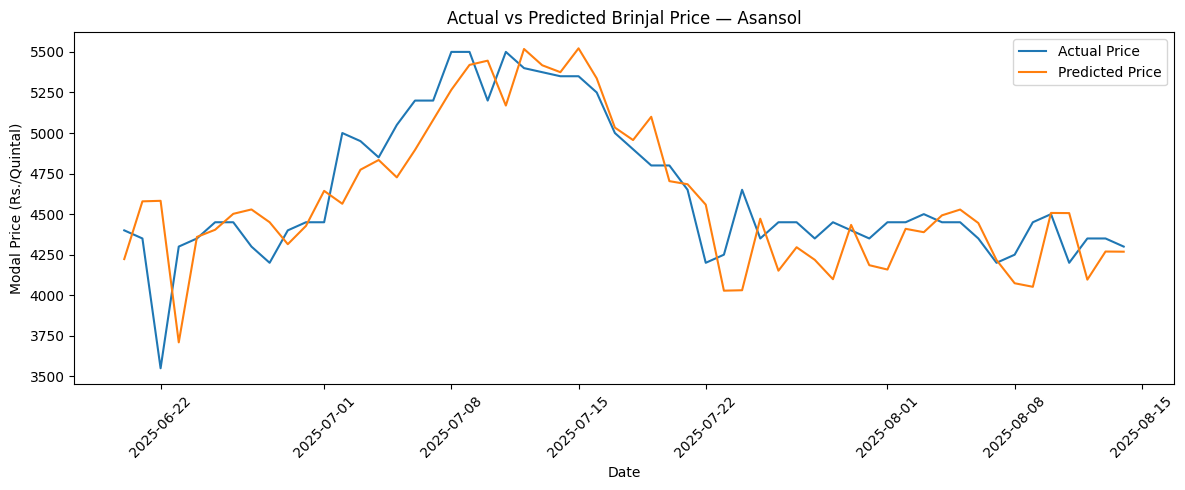

In [146]:
plot_df = test_df[
    ["Price Date", "Commodity", "Market Name", "Modal_Price"]
].copy()

plot_df["Predicted_Price"] = weather_pred

# Show one representative series for visualization
plot_series = plot_df[
    (plot_df["Commodity"] == "Brinjal") &
    (plot_df["Market Name"] == "Asansol")
].sort_values("Price Date")

plt.figure(figsize=(12, 5))

plt.plot(
    plot_series["Price Date"],
    plot_series["Modal_Price"],
    label="Actual Price"
)

plt.plot(
    plot_series["Price Date"],
    plot_series["Predicted_Price"],
    label="Predicted Price"
)

plt.xlabel("Date")
plt.ylabel("Modal Price (Rs./Quintal)")
plt.title("Actual vs Predicted Brinjal Price — Asansol")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## SARIMA Forecasting

In [147]:
import statsmodels.api as sm

print("Statsmodels imported successfully.")

Statsmodels imported successfully.


In [148]:
sarima_series = daily_df[
    (daily_df["Commodity"] == "Brinjal") &
    (daily_df["Market Name"] == "Asansol")
].copy()

sarima_series = (
    sarima_series
    .sort_values("Price Date")
    .set_index("Price Date")["Modal_Price"]
)

sarima_train = sarima_series[
    sarima_series.index < split_date
]

sarima_test = sarima_series[
    sarima_series.index >= split_date
]

print("Training observations:", len(sarima_train))
print("Testing observations:", len(sarima_test))

print("\nTraining period:")
print(sarima_train.index.min(), "to", sarima_train.index.max())

print("\nTesting period:")
print(sarima_test.index.min(), "to", sarima_test.index.max())

Training observations: 309
Testing observations: 56

Training period:
2024-08-15 00:00:00 to 2025-06-19 00:00:00

Testing period:
2025-06-20 00:00:00 to 2025-08-14 00:00:00


In [149]:
sarima_train_daily = sarima_train.asfreq("D")

sarima_model = sm.tsa.statespace.SARIMAX(
    sarima_train_daily,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(
    disp=False,
    maxiter=200
)

print("SARIMA model trained successfully.")
print("Converged:", sarima_result.mle_retvals.get("converged"))

SARIMA model trained successfully.
Converged: True


## Evaluating SARIMA Model

In [150]:
sarima_forecast = sarima_result.forecast(
    steps=len(sarima_test)
)

sarima_mae = mean_absolute_error(
    sarima_test,
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        sarima_test,
        sarima_forecast
    )
)

sarima_mape = (
    np.mean(
        np.abs(
            (sarima_test - sarima_forecast)
            / sarima_test
        )
    ) * 100
)

print("SARIMA — Brinjal / Asansol")
print("--------------------------")
print("MAE :", round(sarima_mae, 2))
print("RMSE:", round(sarima_rmse, 2))
print("MAPE:", round(sarima_mape, 2), "%")

SARIMA — Brinjal / Asansol
--------------------------
MAE : 440.26
RMSE: 500.89
MAPE: 9.51 %


In [151]:
same_series = (
    (test_df["Commodity"] == "Brinjal") &
    (test_df["Market Name"] == "Asansol")
)

actual_same = test_df.loc[
    same_series, "Modal_Price"
]

price_only_same = price_only_pred[same_series.values]
weather_same = weather_pred[same_series.values]

lgb_price_mae = mean_absolute_error(
    actual_same,
    price_only_same
)

lgb_price_rmse = np.sqrt(
    mean_squared_error(
        actual_same,
        price_only_same
    )
)

lgb_price_mape = (
    np.mean(
        np.abs(
            (actual_same - price_only_same)
            / actual_same
        )
    ) * 100
)

lgb_weather_mae = mean_absolute_error(
    actual_same,
    weather_same
)

lgb_weather_rmse = np.sqrt(
    mean_squared_error(
        actual_same,
        weather_same
    )
)

lgb_weather_mape = (
    np.mean(
        np.abs(
            (actual_same - weather_same)
            / actual_same
        )
    ) * 100
)

print("Brinjal / Asansol — LightGBM Price Only")
print("MAE :", round(lgb_price_mae, 2))
print("RMSE:", round(lgb_price_rmse, 2))
print("MAPE:", round(lgb_price_mape, 2), "%")

print("\nBrinjal / Asansol — LightGBM Price + Weather")
print("MAE :", round(lgb_weather_mae, 2))
print("RMSE:", round(lgb_weather_rmse, 2))
print("MAPE:", round(lgb_weather_mape, 2), "%")

Brinjal / Asansol — LightGBM Price Only
MAE : 192.5
RMSE: 256.72
MAPE: 4.28 %

Brinjal / Asansol — LightGBM Price + Weather
MAE : 188.09
RMSE: 260.96
MAPE: 4.2 %


## Prophet model availability check

In [152]:
try:
    import prophet
    print("Prophet is available.")
except ImportError:
    print("Prophet is not installed.")

Prophet is available.


In [153]:
from prophet import Prophet

prophet_train = sarima_train.reset_index()

prophet_train.columns = ["ds", "y"]

prophet_test = sarima_test.reset_index()

prophet_test.columns = ["ds", "y"]

print("Prophet training rows:", len(prophet_train))
print("Prophet testing rows:", len(prophet_test))

display(prophet_train.head())

Prophet training rows: 309
Prophet testing rows: 56


,ds,y
0,2024-08-15,4300.0
1,2024-08-16,5000.0
2,2024-08-17,4000.0
3,2024-08-18,3700.0
4,2024-08-19,3900.0


In [154]:
prophet_model = Prophet(
    weekly_seasonality=True,
    daily_seasonality=False,
    yearly_seasonality=True
)

prophet_model.fit(prophet_train)

print("Prophet model trained successfully.")

09:59:40 - cmdstanpy - INFO - Chain [1] start processing
09:59:40 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully.


## Evaluating the prophet model

In [155]:
future = prophet_test[["ds"]].copy()

prophet_forecast = prophet_model.predict(future)

prophet_pred = prophet_forecast["yhat"].values

prophet_mae = mean_absolute_error(
    prophet_test["y"],
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_test["y"],
        prophet_pred
    )
)

prophet_mape = (
    np.mean(
        np.abs(
            (prophet_test["y"] - prophet_pred)
            / prophet_test["y"]
        )
    ) * 100
)

print("Prophet — Brinjal / Asansol")
print("---------------------------")
print("MAE :", round(prophet_mae, 2))
print("RMSE:", round(prophet_rmse, 2))
print("MAPE:", round(prophet_mape, 2), "%")

Prophet — Brinjal / Asansol
---------------------------
MAE : 2705.7
RMSE: 3115.38
MAPE: 57.28 %


In [156]:
final_comparison = pd.DataFrame({
    "Model": [
        "SARIMA",
        "Prophet",
        "LightGBM — Price Only",
        "LightGBM — Price + Weather"
    ],
    "MAE": [
        sarima_mae,
        prophet_mae,
        lgb_price_mae,
        lgb_weather_mae
    ],
    "RMSE": [
        sarima_rmse,
        prophet_rmse,
        lgb_price_rmse,
        lgb_weather_rmse
    ],
    "MAPE": [
        sarima_mape,
        prophet_mape,
        lgb_price_mape,
        lgb_weather_mape
    ]
})

display(final_comparison.round(2))

,Model,MAE,RMSE,MAPE
0,SARIMA,440.26,500.89,9.51
1,Prophet,2705.70,3115.38,57.28
2,LightGBM — Price Only,192.50,256.72,4.28
3,LightGBM — Price + Weather,188.09,260.96,4.20


In [157]:
commodity_results = []

evaluation_df = test_df[
    ["Commodity", "Market Name", "Modal_Price"]
].copy()

evaluation_df["Prediction"] = weather_pred

for commodity in selected_commodities:

    subset = evaluation_df[
        evaluation_df["Commodity"] == commodity
    ]

    mae = mean_absolute_error(
        subset["Modal_Price"],
        subset["Prediction"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            subset["Modal_Price"],
            subset["Prediction"]
        )
    )

    mape = (
        np.mean(
            np.abs(
                (subset["Modal_Price"] - subset["Prediction"])
                / subset["Modal_Price"]
            )
        ) * 100
    )

    commodity_results.append({
        "Commodity": commodity,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

commodity_results_df = pd.DataFrame(commodity_results)

display(commodity_results_df.round(2))

,Commodity,MAE,RMSE,MAPE
0,Wheat,18.29,22.86,0.68
1,Maize,100.20,148.17,5.04
2,Brinjal,384.55,515.44,7.35


In [158]:
# Verify the latest available data for each selected series

latest_data = (
    model_df
    .groupby(["Commodity", "Market Name"])["Price Date"]
    .max()
    .reset_index()
    .sort_values(["Commodity", "Market Name"])
)

print("Latest available date by commodity-market series:")
display(latest_data)

Latest available date by commodity-market series:


,Commodity,Market Name,Price Date
0,Brinjal,Asansol,2025-08-14
1,Brinjal,Birbhum,2025-08-14
2,Brinjal,Bishnupur(Bankura),2025-08-14
3,Brinjal,Kalipur,2025-08-13
4,Brinjal,Khatra,2025-08-14
5,Maize,Anjad,2025-08-14
6,Maize,Bhikangaon,2025-08-14
7,Maize,Dhamnod,2025-08-14
8,Maize,Khargone,2025-08-14
9,Maize,Manawar,2025-08-14


## Building recursive forecasting pattern

In [159]:
def forecast_future(
    commodity,
    market,
    horizon=7
):
    
    # Get historical data for the selected series
    history = daily_df[
        (daily_df["Commodity"] == commodity) &
        (daily_df["Market Name"] == market)
    ].copy()
    
    history = (
        history
        .sort_values("Price Date")
        [["Price Date", "Modal_Price"]]
        .copy()
    )
    
    # Store predictions
    predictions = []
    
    for _ in range(horizon):
        
        next_date = (
            history["Price Date"].max()
            + pd.Timedelta(days=1)
        )
        
        prices = history["Modal_Price"]
        
        # Create features using only previous observations
        row = {
            "Day_of_Week": next_date.dayofweek,
            "Month": next_date.month,
            "Week_of_Year": next_date.isocalendar().week,
            "Lag_1": prices.iloc[-1],
            "Lag_7": prices.iloc[-7],
            "Lag_14": prices.iloc[-14],
            "Lag_30": prices.iloc[-30],
            "Rolling_Mean_7": prices.iloc[-7:].mean(),
            "Rolling_Std_7": prices.iloc[-7:].std(),
            "Rolling_Mean_30": prices.iloc[-30:].mean(),
            "Rolling_Std_30": prices.iloc[-30:].std(),
            "Commodity": commodity,
            "Market Name": market
        }
        
        X_future = pd.DataFrame([row])
        
        # Match categorical data type used during training
        for col in categorical_features:
            X_future[col] = X_future[col].astype("category")
        
        # Predict next day's price
        prediction = model_price_only.predict(X_future)[0]
        
        # Add prediction to history for recursive forecasting
        history = pd.concat([
            history,
            pd.DataFrame({
                "Price Date": [next_date],
                "Modal_Price": [prediction]
            })
        ], ignore_index=True)
        
        predictions.append({
            "Price Date": next_date,
            "Predicted_Price": prediction
        })
    
    return pd.DataFrame(predictions)

In [160]:
forecast_7_days = forecast_future(
    commodity="Brinjal",
    market="Asansol",
    horizon=7
)

display(forecast_7_days)

,Price Date,Predicted_Price
0,2025-08-15,4183.027915
1,2025-08-16,3968.511254
2,2025-08-17,3830.373131
3,2025-08-18,3785.734104
4,2025-08-19,3848.980398
5,2025-08-20,3822.003057
6,2025-08-21,3787.949750


## Historical price and future forecast

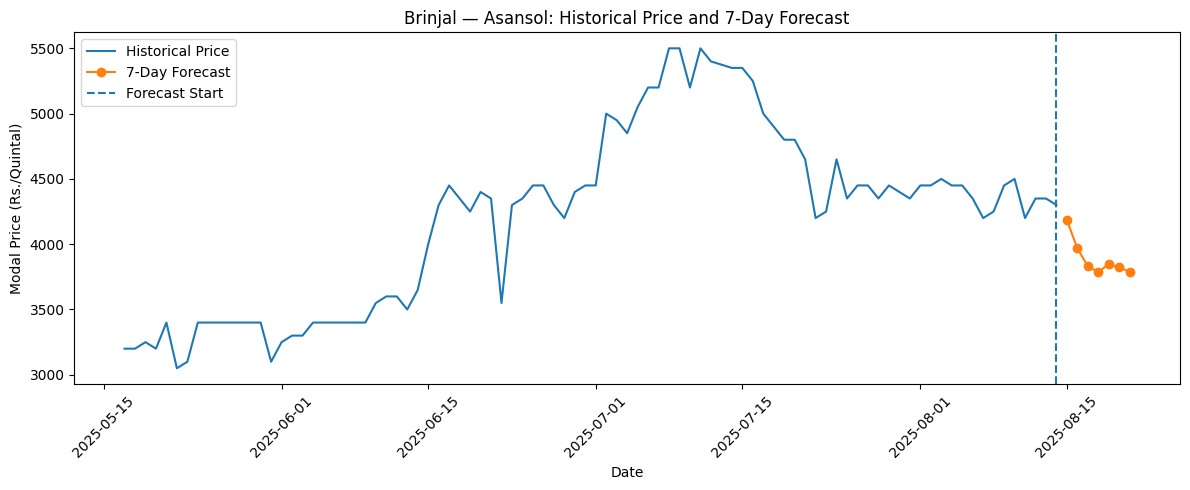

In [161]:
history_plot = daily_df[
    (daily_df["Commodity"] == "Brinjal") &
    (daily_df["Market Name"] == "Asansol")
].copy()

history_plot = history_plot.sort_values("Price Date")

plt.figure(figsize=(12, 5))

plt.plot(
    history_plot["Price Date"].tail(90),
    history_plot["Modal_Price"].tail(90),
    label="Historical Price"
)

plt.plot(
    forecast_7_days["Price Date"],
    forecast_7_days["Predicted_Price"],
    marker="o",
    label="7-Day Forecast"
)

plt.axvline(
    history_plot["Price Date"].max(),
    linestyle="--",
    label="Forecast Start"
)

plt.xlabel("Date")
plt.ylabel("Modal Price (Rs./Quintal)")
plt.title("Brinjal — Asansol: Historical Price and 7-Day Forecast")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Market price comparison

In [162]:
latest_market_prices = (
    daily_df
    .sort_values("Price Date")
    .groupby(["Commodity", "Market Name"], as_index=False)
    .tail(1)
    [["Commodity", "Market Name", "Price Date", "Modal_Price"]]
    .sort_values(["Commodity", "Modal_Price"])
    .reset_index(drop=True)
)

display(latest_market_prices)

,Commodity,Market Name,Price Date,Modal_Price
0,Brinjal,Asansol,2025-08-14,4300.0
1,Brinjal,Khatra,2025-08-14,5000.0
2,Brinjal,Bishnupur(Bankura),2025-08-14,5000.0
3,Brinjal,Kalipur,2025-08-13,5800.0
4,Brinjal,Birbhum,2025-08-14,6400.0
5,Maize,Khargone,2025-08-14,2135.0
6,Maize,Bhikangaon,2025-08-14,2152.0
7,Maize,Anjad,2025-08-14,2211.0
8,Maize,Dhamnod,2025-08-14,2250.0
9,Maize,Manawar,2025-08-14,2315.0


## Market Comparison KPIs

In [163]:
market_kpis = (
    latest_market_prices
    .groupby("Commodity")
    .agg(
        Cheapest_Market=("Market Name", "first"),
        Lowest_Price=("Modal_Price", "first"),
        Costliest_Market=("Market Name", "last"),
        Highest_Price=("Modal_Price", "last")
    )
    .reset_index()
)

market_kpis["Price_Spread"] = (
    market_kpis["Highest_Price"] -
    market_kpis["Lowest_Price"]
)

market_kpis["Spread_Percent"] = (
    market_kpis["Price_Spread"] /
    market_kpis["Lowest_Price"] * 100
)

display(market_kpis.round(2))

,Commodity,Cheapest_Market,Lowest_Price,Costliest_Market,Highest_Price,Price_Spread,Spread_Percent
0,Brinjal,Asansol,4300.0,Birbhum,6400.0,2100.0,48.84
1,Maize,Khargone,2135.0,Manawar,2315.0,180.0,8.43
2,Wheat,Raibareilly,2475.0,Bishnupur(Bankura),3000.0,525.0,21.21


## Visualising Market Price Comparison

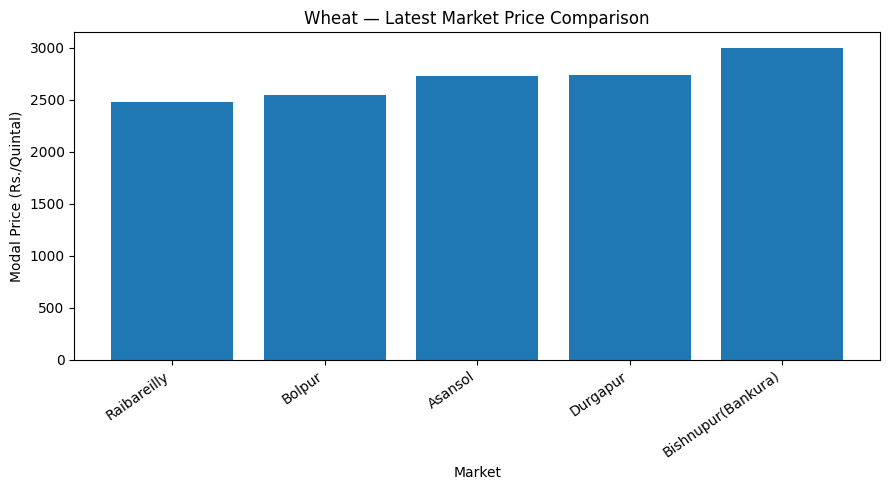

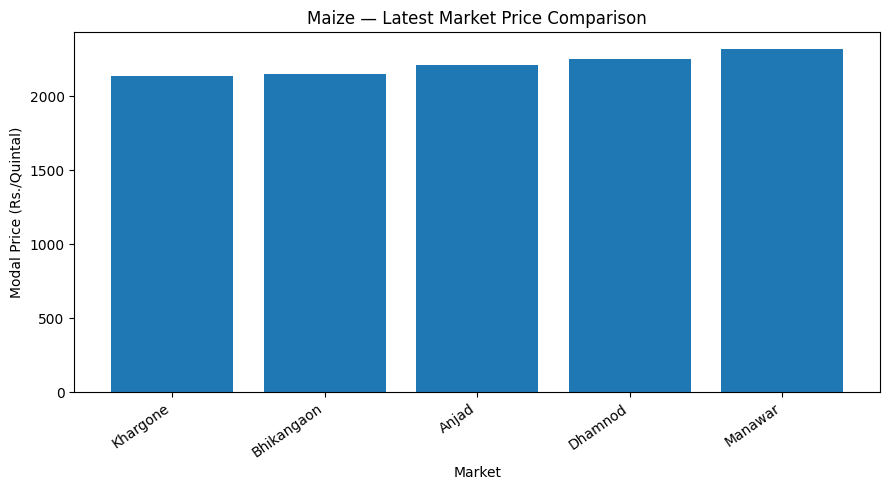

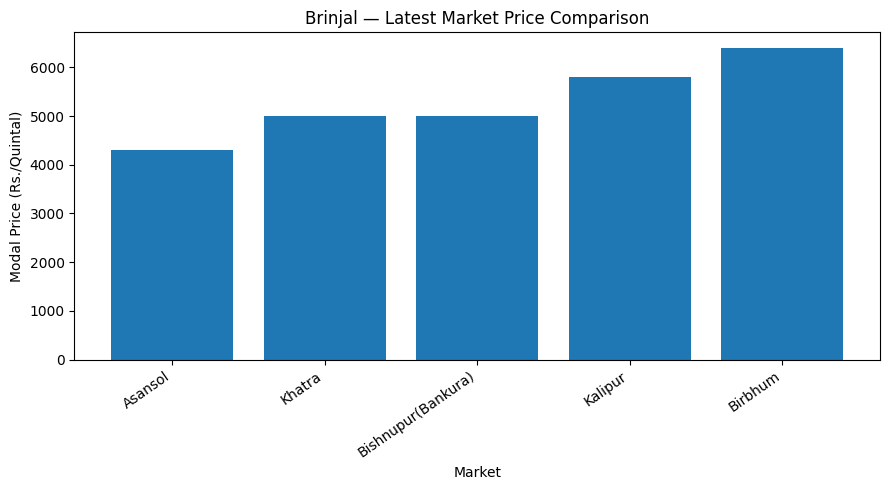

In [164]:
for commodity in selected_commodities:

    plot_data = latest_market_prices[
        latest_market_prices["Commodity"] == commodity
    ].sort_values("Modal_Price")

    plt.figure(figsize=(9, 5))

    plt.bar(
        plot_data["Market Name"],
        plot_data["Modal_Price"]
    )

    plt.xlabel("Market")
    plt.ylabel("Modal Price (Rs./Quintal)")
    plt.title(f"{commodity} — Latest Market Price Comparison")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

## Preparing Dashboard Smmary Data

In [165]:
dashboard_summary = market_kpis.copy()

dashboard_summary = dashboard_summary[
    [
        "Commodity",
        "Cheapest_Market",
        "Lowest_Price",
        "Costliest_Market",
        "Highest_Price",
        "Price_Spread",
        "Spread_Percent"
    ]
]

display(dashboard_summary.round(2))

,Commodity,Cheapest_Market,Lowest_Price,Costliest_Market,Highest_Price,Price_Spread,Spread_Percent
0,Brinjal,Asansol,4300.0,Birbhum,6400.0,2100.0,48.84
1,Maize,Khargone,2135.0,Manawar,2315.0,180.0,8.43
2,Wheat,Raibareilly,2475.0,Bishnupur(Bankura),3000.0,525.0,21.21


## Seven Day Price Change

In [166]:
price_change_data = []

for (commodity, market), group in daily_df.groupby(
    ["Commodity", "Market Name"]
):
    
    group = group.sort_values("Price Date").copy()
    
    latest_price = group["Modal_Price"].iloc[-1]
    
    price_7_days_ago = group["Modal_Price"].iloc[-8]
    
    change = latest_price - price_7_days_ago
    
    change_percent = (
        change / price_7_days_ago
    ) * 100
    
    price_change_data.append({
        "Commodity": commodity,
        "Market Name": market,
        "Latest_Price": latest_price,
        "Price_7_Days_Ago": price_7_days_ago,
        "Change": change,
        "Change_Percent": change_percent
    })

price_change_df = pd.DataFrame(price_change_data)

display(
    price_change_df
    .sort_values(["Commodity", "Market Name"])
    .round(2)
)

,Commodity,Market Name,Latest_Price,Price_7_Days_Ago,Change,Change_Percent
0,Brinjal,Asansol,4300.0,4200.0,100.0,2.38
1,Brinjal,Birbhum,6400.0,4400.0,2000.0,45.45
2,Brinjal,Bishnupur(Bankura),5000.0,4500.0,500.0,11.11
3,Brinjal,Kalipur,5800.0,4600.0,1200.0,26.09
4,Brinjal,Khatra,5000.0,4500.0,500.0,11.11
5,Maize,Anjad,2211.0,1962.5,248.5,12.66
6,Maize,Bhikangaon,2152.0,2090.0,62.0,2.97
7,Maize,Dhamnod,2250.0,2250.0,0.0,0.00
8,Maize,Khargone,2135.0,2200.0,-65.0,-2.95
9,Maize,Manawar,2315.0,2250.0,65.0,2.89


## Final Dashboard KPI Dataset

In [167]:
dashboard_kpis = daily_df.copy()

# Price exactly 7 days earlier for each commodity-market series
dashboard_kpis["Price_7_Days_Ago"] = (
    dashboard_kpis
    .groupby(["Commodity", "Market Name"])["Modal_Price"]
    .shift(7)
)

# Percentage change
dashboard_kpis["Change_7_Days_Percent"] = (
    (
        dashboard_kpis["Modal_Price"]
        - dashboard_kpis["Price_7_Days_Ago"]
    )
    / dashboard_kpis["Price_7_Days_Ago"]
) * 100

# Keep only the latest available observation for each series
dashboard_kpis = (
    dashboard_kpis
    .sort_values("Price Date")
    .groupby(["Commodity", "Market Name"], as_index=False)
    .tail(1)
    .copy()
)

dashboard_kpis = dashboard_kpis[
    [
        "Commodity",
        "Market Name",
        "Price Date",
        "Modal_Price",
        "Price_7_Days_Ago",
        "Change_7_Days_Percent"
    ]
].rename(columns={
    "Modal_Price": "Latest_Price"
})

dashboard_kpis = dashboard_kpis.sort_values(
    ["Commodity", "Latest_Price"]
).reset_index(drop=True)

display(dashboard_kpis.round(2))

,Commodity,Market Name,Price Date,Latest_Price,Price_7_Days_Ago,Change_7_Days_Percent
0,Brinjal,Asansol,2025-08-14,4300.0,4200.0,2.38
1,Brinjal,Khatra,2025-08-14,5000.0,4500.0,11.11
2,Brinjal,Bishnupur(Bankura),2025-08-14,5000.0,4500.0,11.11
3,Brinjal,Kalipur,2025-08-13,5800.0,4600.0,26.09
4,Brinjal,Birbhum,2025-08-14,6400.0,4400.0,45.45
5,Maize,Khargone,2025-08-14,2135.0,2200.0,-2.95
6,Maize,Bhikangaon,2025-08-14,2152.0,2090.0,2.97
7,Maize,Anjad,2025-08-14,2211.0,1962.5,12.66
8,Maize,Dhamnod,2025-08-14,2250.0,2250.0,0.00
9,Maize,Manawar,2025-08-14,2315.0,2250.0,2.89


## Combine Dashboard and Market price indicators

In [168]:
dashboard_data = dashboard_kpis.merge(
    market_kpis,
    on="Commodity",
    how="left"
)

dashboard_data = dashboard_data[
    [
        "Commodity",
        "Market Name",
        "Price Date",
        "Latest_Price",
        "Price_7_Days_Ago",
        "Change_7_Days_Percent",
        "Cheapest_Market",
        "Lowest_Price",
        "Costliest_Market",
        "Highest_Price",
        "Price_Spread",
        "Spread_Percent"
    ]
]

display(dashboard_data.round(2))

,Commodity,Market Name,Price Date,Latest_Price,Price_7_Days_Ago,Change_7_Days_Percent,Cheapest_Market,Lowest_Price,Costliest_Market,Highest_Price,Price_Spread,Spread_Percent
0,Brinjal,Asansol,2025-08-14,4300.0,4200.0,2.38,Asansol,4300.0,Birbhum,6400.0,2100.0,48.84
1,Brinjal,Khatra,2025-08-14,5000.0,4500.0,11.11,Asansol,4300.0,Birbhum,6400.0,2100.0,48.84
2,Brinjal,Bishnupur(Bankura),2025-08-14,5000.0,4500.0,11.11,Asansol,4300.0,Birbhum,6400.0,2100.0,48.84
3,Brinjal,Kalipur,2025-08-13,5800.0,4600.0,26.09,Asansol,4300.0,Birbhum,6400.0,2100.0,48.84
4,Brinjal,Birbhum,2025-08-14,6400.0,4400.0,45.45,Asansol,4300.0,Birbhum,6400.0,2100.0,48.84
5,Maize,Khargone,2025-08-14,2135.0,2200.0,-2.95,Khargone,2135.0,Manawar,2315.0,180.0,8.43
6,Maize,Bhikangaon,2025-08-14,2152.0,2090.0,2.97,Khargone,2135.0,Manawar,2315.0,180.0,8.43
7,Maize,Anjad,2025-08-14,2211.0,1962.5,12.66,Khargone,2135.0,Manawar,2315.0,180.0,8.43
8,Maize,Dhamnod,2025-08-14,2250.0,2250.0,0.00,Khargone,2135.0,Manawar,2315.0,180.0,8.43
9,Maize,Manawar,2025-08-14,2315.0,2250.0,2.89,Khargone,2135.0,Manawar,2315.0,180.0,8.43


In [169]:
import joblib

# Save the trained price-only LightGBM model
joblib.dump(
    model_price_only,
    "agriscope_lightgbm_model.pkl"
)

# Save dashboard-ready datasets
daily_df.to_csv(
    "agriscope_daily_data.csv",
    index=False
)

dashboard_data.to_csv(
    "agriscope_dashboard_data.csv",
    index=False
)

print("AgriScope dashboard artifacts saved successfully.")

AgriScope dashboard artifacts saved successfully.


## 20. Interactive AgriScope Streamlit Dashboard

### Overview
We package the trained LightGBM models, processed time-series, and micro-climate overlays into a responsive **Streamlit dashboard** (`app.py`).

**Core Dashboard Features:**
- **Mandi & Commodity Selection:** Dynamically switch across Wheat, Maize, and Brinjal across top mandis.
- **Real-Time KPIs:** Latest modal price, 7-day price percentage change, and historical price spread.
- **Historical Moving Averages:** 7-day and 30-day moving average trend lines.
- **Multi-Step ML Forecasting:** 1 to 30-day recursive LightGBM price predictions.
- **Micro-Climate Impact:** Historical daily mean temperature and rainfall overlay.
- **Academic Benchmark Card:** Comprehensive MAE, RMSE, and MAPE comparative metrics across Naive, LightGBM, and SARIMA models.

In [ ]:
!pip install -q streamlit plotly


In [ ]:
%%writefile app.py

import os
import pickle
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

# ---------------------------------------------------------
# Page Configuration & Styling
# ---------------------------------------------------------
st.set_page_config(
    page_title="AgriScope — Agricultural Market Price Analyzer",
    page_icon="🌾",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Custom Styling (Scoped so it does not interfere with st.metric or st.dataframe)
st.markdown("""
<style>
    .main-title {
        font-size: 2.2rem;
        font-weight: 800;
        color: #1b5e20;
        margin-bottom: 0px;
    }
    .sub-title {
        font-size: 1.05rem;
        color: #424242;
        margin-bottom: 20px;
    }
    .section-header {
        font-size: 1.3rem;
        font-weight: 700;
        color: #2e7d32;
        border-bottom: 2px solid #c8e6c9;
        padding-bottom: 5px;
        margin-top: 25px;
        margin-bottom: 15px;
    }
    .badge-card {
        background-color: #f1f8e9;
        border-radius: 8px;
        padding: 12px 16px;
        border-left: 4px solid #43a047;
        margin-bottom: 15px;
    }
</style>
""", unsafe_allow_html=True)


# ---------------------------------------------------------
# Data & Model Loader
# ---------------------------------------------------------
@st.cache_data
def load_data():
    file_path = "agriscope_processed_model_data.csv"
    if not os.path.exists(file_path):
        st.error(f"Processed dataset '{file_path}' not found. Please run the notebook/pipeline first.")
        st.stop()
    df = pd.read_csv(file_path)
    df["Price Date"] = pd.to_datetime(df["Price Date"])
    return df

@st.cache_resource
def load_model():
    model_path = "lgb_model.pkl"
    if not os.path.exists(model_path):
        return None
    with open(model_path, "rb") as f:
        model = pickle.load(f)
    return model

data_df = load_data()
model = load_model()

# ---------------------------------------------------------
# Sidebar: User Controls
# ---------------------------------------------------------
st.sidebar.image("https://images.unsplash.com/photo-1500937386664-56d1dfef3854?auto=format&fit=crop&w=400&q=80", use_container_width=True)
st.sidebar.title("🌾 AgriScope Controls")

commodities = sorted(data_df["Commodity"].unique().tolist())
selected_commodity = st.sidebar.selectbox("Select Commodity", commodities, index=0)

available_markets = sorted(
    data_df[data_df["Commodity"] == selected_commodity]["Market Name"].unique().tolist()
)
selected_market = st.sidebar.selectbox("Select Mandi (Market)", available_markets, index=0)

# Replace slider with number_input to prevent dynamic JS module import errors
forecast_days = st.sidebar.number_input(
    "Forecast Horizon (days)",
    min_value=1,
    max_value=30,
    value=7,
    step=1,
    help="Select how many future days to forecast using recursive LightGBM."
)

show_weather = st.sidebar.checkbox("Show Historical Weather Overlay", value=True)

st.sidebar.markdown("---")
st.sidebar.markdown("""
**Project:** AgriScope (P_085)  
**Dataset:** AGMARKNET & Open-Meteo  
**Models:** Seasonal Naive, LightGBM, SARIMA  
""")

# ---------------------------------------------------------
# Filter Historical Data for Selected Series
# ---------------------------------------------------------
series_df = data_df[
    (data_df["Commodity"] == selected_commodity) & 
    (data_df["Market Name"] == selected_market)
].sort_values("Price Date").copy()

if series_df.empty:
    st.warning("No data found for the selected Commodity and Market combination.")
    st.stop()

# ---------------------------------------------------------
# Header & Context
# ---------------------------------------------------------
st.markdown('<div class="main-title">🌾 AgriScope — Agricultural Market Price Analyzer</div>', unsafe_allow_html=True)
st.markdown(f'<div class="sub-title">Real-Time Mandi Analysis, Micro-Climate Correlation & ML Price Forecasting for <b>{selected_commodity}</b> at <b>{selected_market}</b></div>', unsafe_allow_html=True)

# ---------------------------------------------------------
# Section 1: Key Performance Indicators (Native st.metric)
# ---------------------------------------------------------
latest_row = series_df.iloc[-1]
latest_price = latest_row["Modal_Price"]
latest_date = latest_row["Price Date"]

# Calculate 7-day change
if len(series_df) >= 8:
    prev_7_price = series_df.iloc[-8]["Modal_Price"]
    pct_change_7d = ((latest_price - prev_7_price) / prev_7_price) * 100
    delta_7d = f"{pct_change_7d:+.1f}% vs 7d ago"
else:
    delta_7d = None

mandi_min_price = series_df["Modal_Price"].min()
mandi_max_price = series_df["Modal_Price"].max()
price_spread = mandi_max_price - mandi_min_price

kpi1, kpi2, kpi3, kpi4 = st.columns(4)

with kpi1:
    st.metric(
        label="Latest Modal Price",
        value=f"₹{latest_price:,.0f}/quintal",
        delta=delta_7d
    )

with kpi2:
    st.metric(
        label="Reporting Period",
        value=f"{len(series_df)} Days",
        delta=f"From {series_df['Price Date'].min().strftime('%d %b %Y')}"
    )

with kpi3:
    st.metric(
        label="Historical Price Range",
        value=f"₹{mandi_min_price:,.0f} – ₹{mandi_max_price:,.0f}",
        delta=f"Spread: ₹{price_spread:,.0f}"
    )

with kpi4:
    st.metric(
        label="Latest Record Date",
        value=latest_date.strftime("%d %b %Y"),
        delta="Official Mandi Log"
    )

# ---------------------------------------------------------
# Section 2: Historical Price Trend & Moving Averages
# ---------------------------------------------------------
st.markdown('<div class="section-header">📈 Historical Price Trend & Volatility Analysis</div>', unsafe_allow_html=True)

fig_hist = go.Figure()

fig_hist.add_trace(go.Scatter(
    x=series_df["Price Date"],
    y=series_df["Modal_Price"],
    mode="lines+markers",
    name="Daily Modal Price",
    line=dict(color="#2e7d32", width=2.5),
    marker=dict(size=4)
))

if "Rolling_Mean_7" in series_df.columns:
    fig_hist.add_trace(go.Scatter(
        x=series_df["Price Date"],
        y=series_df["Rolling_Mean_7"],
        mode="lines",
        name="7-Day Moving Average",
        line=dict(color="#1976d2", width=1.8, dash="dash")
    ))

if "Rolling_Mean_30" in series_df.columns:
    fig_hist.add_trace(go.Scatter(
        x=series_df["Price Date"],
        y=series_df["Rolling_Mean_30"],
        mode="lines",
        name="30-Day Moving Average",
        line=dict(color="#f57c00", width=1.8, dash="dot")
    ))

fig_hist.update_layout(
    title=f"Historical Price Movement — {selected_commodity} ({selected_market})",
    xaxis_title="Date",
    yaxis_title="Price (₹ / Quintal)",
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    margin=dict(l=20, r=20, t=50, b=20),
    template="plotly_white"
)

st.plotly_chart(fig_hist, use_container_width=True)

# ---------------------------------------------------------
# Section 3: Machine Learning Future Price Forecast
# ---------------------------------------------------------
st.markdown(f'<div class="section-header">🤖 ML Price Forecast ({forecast_days}-Day Recursive Horizon)</div>', unsafe_allow_html=True)

def generate_forecast(trained_model, hist_df, commodity, market, horizon):
    prices = hist_df["Modal_Price"].tolist()
    dates = hist_df["Price Date"].tolist()
    last_dt = dates[-1]
    
    forecast_list = []
    
    for step in range(1, horizon + 1):
        target_dt = last_dt + pd.Timedelta(days=step)
        
        lag_1 = prices[-1]
        lag_7 = prices[-7] if len(prices) >= 7 else prices[0]
        lag_14 = prices[-14] if len(prices) >= 14 else prices[0]
        lag_30 = prices[-30] if len(prices) >= 30 else prices[0]
        
        roll_7_m = float(np.mean(prices[-7:]))
        roll_7_s = float(np.std(prices[-7:]))
        roll_30_m = float(np.mean(prices[-30:]))
        roll_30_s = float(np.std(prices[-30:]))
        
        feat_row = {
            "Day_of_Week": [target_dt.dayofweek],
            "Month": [target_dt.month],
            "Week_of_Year": [int(target_dt.isocalendar().week)],
            "Lag_1": [lag_1],
            "Lag_7": [lag_7],
            "Lag_14": [lag_14],
            "Lag_30": [lag_30],
            "Rolling_Mean_7": [roll_7_m],
            "Rolling_Std_7": [roll_7_s],
            "Rolling_Mean_30": [roll_30_m],
            "Rolling_Std_30": [roll_30_s],
            "Commodity": pd.Series([commodity], dtype="category"),
            "Market Name": pd.Series([market], dtype="category"),
            "temperature_2m_mean": [hist_df["temperature_2m_mean"].iloc[-1] if "temperature_2m_mean" in hist_df else 28.0],
            "temperature_2m_max": [hist_df["temperature_2m_max"].iloc[-1] if "temperature_2m_max" in hist_df else 33.0],
            "temperature_2m_min": [hist_df["temperature_2m_min"].iloc[-1] if "temperature_2m_min" in hist_df else 23.0],
            "precipitation_sum": [hist_df["precipitation_sum"].iloc[-1] if "precipitation_sum" in hist_df else 0.0],
            "wind_speed_10m_max": [hist_df["wind_speed_10m_max"].iloc[-1] if "wind_speed_10m_max" in hist_df else 12.0]
        }
        
        X_df = pd.DataFrame(feat_row)
        
        if trained_model is not None:
            pred_p = float(trained_model.predict(X_df)[0])
        else:
            # Fallback autoregressive estimate if model binary missing
            pred_p = 0.6 * lag_1 + 0.3 * roll_7_m + 0.1 * lag_7
            
        prices.append(pred_p)
        forecast_list.append({
            "Date": target_dt.strftime("%Y-%m-%d"),
            "Forecasted Modal Price (₹/Quintal)": round(pred_p, 2),
            "Estimated Daily Volatility (₹)": round(roll_7_s, 2)
        })
        
    return pd.DataFrame(forecast_list)

forecast_table = generate_forecast(model, series_df, selected_commodity, selected_market, int(forecast_days))

# Forecast Metrics
f_start = forecast_table.iloc[0]["Forecasted Modal Price (₹/Quintal)"]
f_end = forecast_table.iloc[-1]["Forecasted Modal Price (₹/Quintal)"]
f_change = ((f_end - f_start) / f_start) * 100

f1, f2, f3 = st.columns(3)
with f1:
    st.metric("Forecast Start Price", f"₹{f_start:,.2f}/quintal")
with f2:
    st.metric("Forecast Horizon End Price", f"₹{f_end:,.2f}/quintal")
with f3:
    st.metric("Projected Trend Change", f"{f_change:+.2f}%", delta=f"{f_change:+.2f}%")

# Combined Forecast Plot
hist_tail = series_df.tail(45)

fig_fore = go.Figure()

# Recent actuals
fig_fore.add_trace(go.Scatter(
    x=hist_tail["Price Date"],
    y=hist_tail["Modal_Price"],
    mode="lines+markers",
    name="Recent Actual Price",
    line=dict(color="#37474f", width=2.5)
))

# Forecast line
fig_fore.add_trace(go.Scatter(
    x=pd.to_datetime(forecast_table["Date"]),
    y=forecast_table["Forecasted Modal Price (₹/Quintal)"],
    mode="lines+markers",
    name="LightGBM Future Forecast",
    line=dict(color="#d32f2f", width=3, dash="dot"),
    marker=dict(symbol="star", size=8, color="#d32f2f")
))

fig_fore.update_layout(
    title=f"Recent Actuals & {forecast_days}-Day Future Forecast — {selected_commodity} ({selected_market})",
    xaxis_title="Date",
    yaxis_title="Price (₹ / Quintal)",
    hovermode="x unified",
    margin=dict(l=20, r=20, t=50, b=20),
    template="plotly_white"
)

col_fchart, col_ftable = st.columns([3, 2])
with col_fchart:
    st.plotly_chart(fig_fore, use_container_width=True)
with col_ftable:
    st.markdown("**📋 Forecasted Schedule:**")
    # Native st.dataframe without .to_html() to fix Bug B
    st.dataframe(forecast_table, use_container_width=True, hide_index=True)

# ---------------------------------------------------------
# Section 4: Market-to-Market Comparison
# ---------------------------------------------------------
st.markdown(f'<div class="section-header">⚖️ Market-to-Market Comparison for {selected_commodity}</div>', unsafe_allow_html=True)

# Find latest date per market
comm_df = data_df[data_df["Commodity"] == selected_commodity].copy()
latest_comm_prices = comm_df.sort_values("Price Date").groupby("Market Name").last().reset_index()

lowest_mkt = latest_comm_prices.sort_values("Modal_Price").iloc[0]
highest_mkt = latest_comm_prices.sort_values("Modal_Price").iloc[-1]
mkt_spread = highest_mkt["Modal_Price"] - lowest_mkt["Modal_Price"]

mc1, mc2, mc3 = st.columns(3)
with mc1:
    st.metric("Lowest Price Mandi", f"{lowest_mkt['Market Name']}", delta=f"₹{lowest_mkt['Modal_Price']:,.0f}/quintal", delta_color="inverse")
with mc2:
    st.metric("Highest Price Mandi", f"{highest_mkt['Market Name']}", delta=f"₹{highest_mkt['Modal_Price']:,.0f}/quintal")
with mc3:
    st.metric("Inter-Mandi Spread", f"₹{mkt_spread:,.0f}/quintal", delta=f"{((mkt_spread)/lowest_mkt['Modal_Price'])*100:.1f}% variation")

fig_bar = px.bar(
    latest_comm_prices.sort_values("Modal_Price"),
    x="Market Name",
    y="Modal_Price",
    color="Modal_Price",
    color_continuous_scale="Viridis",
    text_auto=".0f",
    title=f"Latest Modal Price Comparison across Mandis for {selected_commodity}"
)
fig_bar.update_layout(
    xaxis_title="Market Name",
    yaxis_title="Modal Price (₹/Quintal)",
    template="plotly_white",
    margin=dict(l=20, r=20, t=50, b=20)
)
st.plotly_chart(fig_bar, use_container_width=True)

# ---------------------------------------------------------
# Section 5: Historical Weather & Climate Impact
# ---------------------------------------------------------
if show_weather and "temperature_2m_mean" in series_df.columns:
    st.markdown(f'<div class="section-header">🌦️ Historical Weather & Climate Patterns ({selected_market})</div>', unsafe_allow_html=True)
    
    w1, w2, w3, w4 = st.columns(4)
    with w1:
        st.metric("Avg Daily Temperature", f"{series_df['temperature_2m_mean'].mean():.1f} °C")
    with w2:
        st.metric("Max Recorded Temp", f"{series_df['temperature_2m_max'].max():.1f} °C")
    with w3:
        st.metric("Total Precipitation", f"{series_df['precipitation_sum'].sum():.1f} mm")
    with w4:
        st.metric("Peak Daily Rain", f"{series_df['precipitation_sum'].max():.1f} mm")

    fig_w = go.Figure()
    fig_w.add_trace(go.Scatter(
        x=series_df["Price Date"],
        y=series_df["temperature_2m_mean"],
        name="Mean Temp (°C)",
        line=dict(color="#f57c00", width=2)
    ))
    fig_w.add_trace(go.Bar(
        x=series_df["Price Date"],
        y=series_df["precipitation_sum"],
        name="Precipitation (mm)",
        marker_color="#0288d1",
        yaxis="y2",
        opacity=0.6
    ))
    
    fig_w.update_layout(
        title=f"Temperature & Rainfall at {selected_market}",
        xaxis_title="Date",
        yaxis=dict(title="Temperature (°C)", side="left"),
        yaxis2=dict(title="Precipitation (mm)", side="right", overlaying="y"),
        hovermode="x unified",
        template="plotly_white",
        margin=dict(l=20, r=20, t=50, b=20)
    )
    st.plotly_chart(fig_w, use_container_width=True)

# ---------------------------------------------------------
# Section 6: Model Performance Benchmark & Methodology Card
# ---------------------------------------------------------
st.markdown('<div class="section-header">🔬 Academic Benchmark & Evaluation Summary</div>', unsafe_allow_html=True)

st.markdown("""
<div class="badge-card">
<b>Evaluation Protocol:</b> Chronological 56-day holdout validation (20 June 2025 to 14 August 2025) across 15 commodity-market series. No random shuffling or future leakage permitted.
</div>
""", unsafe_allow_html=True)

perf_data = pd.DataFrame({
    "Forecasting Model": [
        "Seasonal Naive Baseline (Lag-7)",
        "LightGBM (Price-Only Features)",
        "LightGBM (Price + Weather)",
        "SARIMA (1,1,1)x(1,1,1,7) [Brinjal-Asansol]"
    ],
    "Scope": ["Aggregate (15 Series)", "Aggregate (15 Series)", "Aggregate (15 Series)", "Single Representative Series"],
    "MAE (₹)": [269.88, 166.22, 167.42, 440.26],
    "RMSE (₹)": [538.92, 317.32, 309.60, 500.89],
    "MAPE (%)": ["6.41%", "4.27%", "4.35%", "9.51%"],
    "Core Finding": [
        "Simple weekly seasonal persistence baseline",
        "Substantial improvement over naive rule via lag & rolling dynamics",
        "Slightly improves RMSE (-2.4%), but slight increase in MAE/MAPE (mixed effect)",
        "Higher error than ML due to linear limitation on abrupt vegetable volatility"
    ]
})

st.dataframe(perf_data, use_container_width=True, hide_index=True)

st.markdown("---")
st.caption("AgriScope System v2.0 | College Data Science Project P_085 | Built with Python, LightGBM, Streamlit & Plotly")


### 🚀 How to Launch the Dashboard

#### Option A: Running Locally (Recommended for Daily Use & Presentation)
Open a terminal in your project directory and execute:
```bash
streamlit run app.py
```
The app opens automatically in your browser at `http://localhost:8501`.

#### Option B: Running in Kaggle / Colab
> **Note on Cloud Tunnels:** Free cloud tunnels (`loca.lt`) are ephemeral and expire as soon as the notebook session finishes or pauses. To launch a temporary session in Kaggle:
```python
# 1. Start Streamlit in background
import subprocess
subprocess.Popen(['streamlit', 'run', 'app.py', '--server.port', '8501', '--server.address', '0.0.0.0'])

# 2. Expose via localtunnel
!npx localtunnel --port 8501
```